In [1]:
import numpy as np
import sympy as sp
from scipy.integrate import quad
import matplotlib.pyplot as plt
import math
import time
from scipy.linalg import hankel
from tqdm import tqdm
import pandas as pd

In [2]:
# n0 = (0.374316, 0.210408)
n0 = (0.05495620,  0.01607373)
tmax = 2000
rsv = 4
numMax = 160001
M = 0.5
L = 2
aGaussiana, bGaussiana = rsv, 3
pertubation_params = (aGaussiana, bGaussiana)
rc = 100.0

In [3]:
def genelist(a, b, n):
    return np.linspace(a, b, int(n))

![alt text](imagens/formulaf.png "Title")

![alt text](imagens/flinha.png "Title")

![alt text](imagens/nr.png "Title")

In [4]:
def findrvalue_vetorizado(rstarlist, M, tol=1e-14, max_iter=100):
    """
    Resolve r* = r + 2M*ln(r/(2M) - 1) para r, dado um array de r*,
    usando Newton-Raphson vetorizado (substitui a bisseção ponto a ponto).
    """
    # chute inicial: para r grande, r* ≈ r (assintoticamente)
    r = np.maximum(rstarlist, 2 * M * 1.001)

    for it in range(max_iter):
        f_r = r + 2 * M * np.log(r / (2 * M) - 1) - rstarlist
        flinha = 1.0 + 2 * M / (r - 2 * M)

        r_new = r - f_r / flinha

        # segurança: nunca deixar cair em r <= 2M (log diverge)
        # a derivada fica muito grande perto do horizonte e o passo de Newton pode ser desproporcional.
        # Se isso acontecer para algum elemento do array, em vez de aceitar esse
        # valor, vamos forçar a média entre o valor atual e 2M.
        r_new = np.where(r_new <= 2 * M, (r + 2 * M) / 2, r_new)

        delta = np.max(np.abs(r_new - r))
        # analisa a diferença maxima entre os valores antigos e novos para todos os elementos do array
        r = r_new

        if delta < tol:
            break
        # else:
        #     # print(f"AVISO: Newton não convergiu em {max_iter} iterações.")
        #     # print(f"Maior delta residual: {delta:.3e}")

    return r

![alt text](imagens/psi2.png "Title")

In [5]:
def V_potencial(rlist, L, M):
        return np.where(
            rlist <= rc,
            (1.0 - 2 * M / rlist) * (L * (L + 1) / rlist**2 - 6 * M / rlist**3),
            0.0,
        )
        # return (1.0 - 2 * M / rlist) * (L * (L + 1) / rlist**2 - 6 * M / rlist**3) sem descontinuidade

In [6]:
def getEvo(tmax, rsv, numMax, M, L, pertubation_params):
    av, bv = pertubation_params

    rsmax = 2 * tmax
    rstarlist = genelist(rsv - rsmax/2.0, rsv + rsmax/2.0, numMax)
    
    hr = float(np.diff(rstarlist[:2])[0])
    ht =0.5 * hr 
    print(f"ht: {ht}")

    inicio = time.time()
    rlist0 = findrvalue_vetorizado(rstarlist, M)
    tempo_execucao  = time.time() - inicio
    print(f"Tempo de execução para encontrar rlist0: {tempo_execucao:.6f} segundos")

    rlist = rlist0

    #Verificação e Aviso
    if np.any(rlist <= rc):
        # Localiza o índice na malha mais próximo do valor exato de rc
        idx_rc = np.argmin(np.abs(rlist - rc))
        r_proximo = rlist[idx_rc]

        print(f"AVISO: O ponto rc = {rc} foi atingido pela malha!")
        print(
            f"   -> Ponto no grid mais próximo: r = {r_proximo:.14f} (Índice: {idx_rc})"
        )
        print(f"   -> Ponto r* correspondente: r* = {rstarlist[idx_rc]:.6f}")
    else:
        print(
            f"O valor rc = {rc} não foi atingido na malha (r_min = {rlist.min():.4f})"
        )


    Vv = V_potencial(rlist, L, M)

    ii = 1
    psi0 = np.zeros(len(rlist))
    psi1 = ht * np.exp(-((rstarlist - av)**2) / (2 * (bv**2)))
    length = int((numMax - 1) / 2)
    psi_collect = np.zeros(length)

    inicio_loop = time.time()
    for ii in tqdm(range(1, length+1), desc="Evoluindo PSI"):
        Vv = Vv[1:-1]
        psi2 = (
            2 * psi1[1:-1] 
            - psi0[1:-1] 
            - (ht**2) * Vv * psi1[1:-1] 
            + (ht**2 / hr**2) * (psi1[:-2] - 2 * psi1[1:-1] + psi1[2:])
        )
        
        psi0 = psi1[1:-1]
        psi1 = psi2

        psi_collect[ii-1] = psi1[length - ii] # armazenando o valor de psi no ponto central da malha para cada passo de tempo
        

    tempo_execucao_loop  = time.time() - inicio_loop
    print(f"Tempo de execução do loop: {tempo_execucao_loop:.6f} segundos")
    return ht, psi_collect


In [7]:
def plotEvolution(test, title=""):

    ht, psi = test

    t = ht * np.arange(1, len(psi)+1)

    plt.figure(figsize=(9,4))
    plt.plot(t, psi, lw=2)

    t_max = t[-1]
    plt.xticks(np.arange(0, t_max + 1, 100))
    plt.xlabel("t")
    plt.ylabel(r"$\Psi$")
    plt.grid(True)
    plt.title(title)
    plt.show()


def plotLogEvolution(test, title=""):

    ht, psi = test

    t = ht * np.arange(1, len(psi)+1)

    plt.figure(figsize=(9,4))

    plt.semilogy(
        t,
        np.abs(psi),
        lw=2
    )

    plt.xlabel(r"$t$ ")
    plt.ylabel(r"$|\Psi|$ (escala log)")

    plt.grid(True)

    plt.title(title)

    plt.show()

ht: 0.012500000000045475
Tempo de execução para encontrar rlist0: 0.576794 segundos
AVISO: O ponto rc = 100.0 foi atingido pela malha!
   -> Ponto no grid mais próximo: r = 100.00483134954551 (Índice: 84024)
   -> Ponto r* correspondente: r* = 104.600000


Evoluindo PSI: 100%|██████████| 80000/80000 [02:54<00:00, 457.17it/s]  


Tempo de execução do loop: 175.049822 segundos


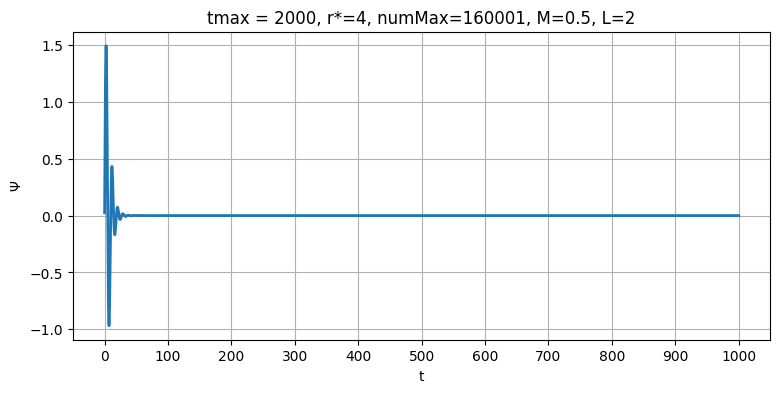

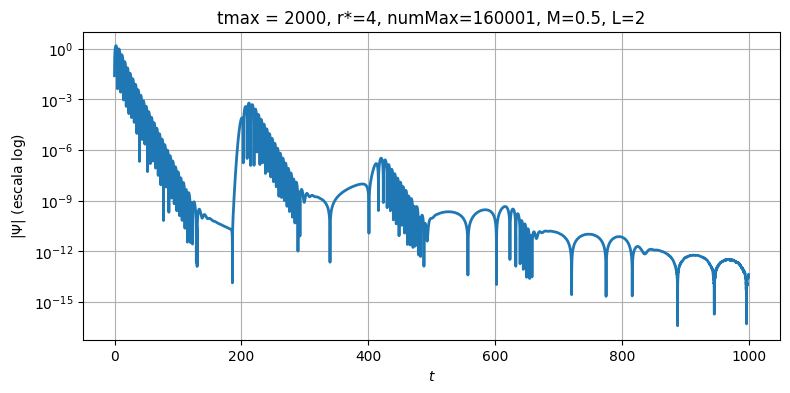

In [8]:
# def getEvo(tmax, rsv, numMax, M, L, pertubation_params):
test1 = getEvo(tmax, rsv, numMax, M, L, pertubation_params)
title_str = f"tmax = {tmax}, r*={rsv}, numMax={numMax}, M={M}, L={L}"
plotEvolution(
    test1,
    title_str
)
plotLogEvolution(
    test1,
    title_str
)

![alt text](imagens\simulacaoonda.png "Title")

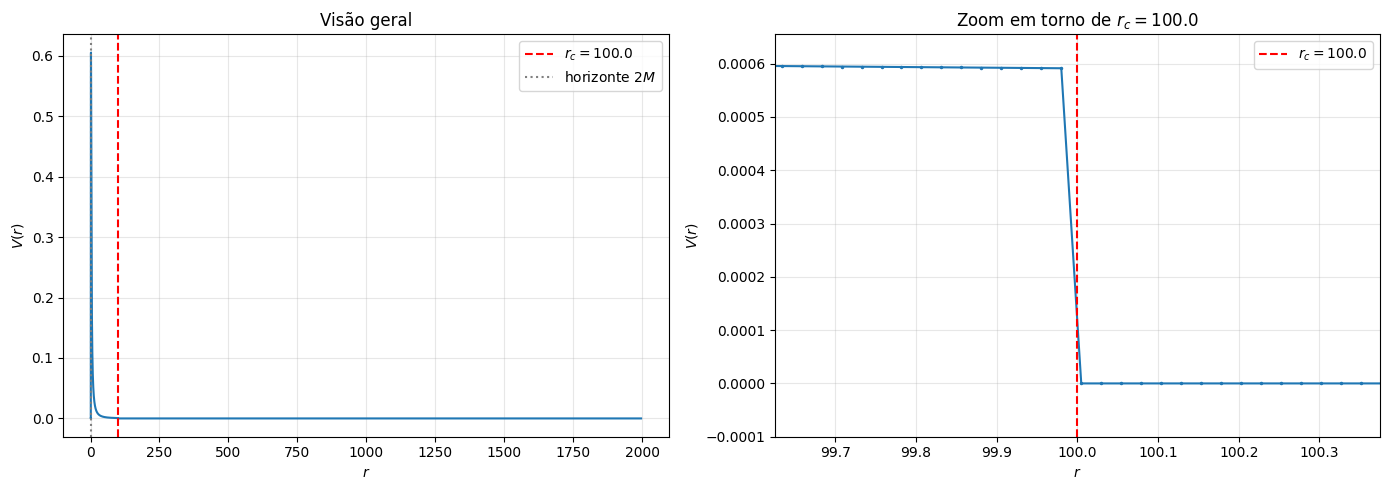

In [9]:
rsmax = 2 * tmax
rstarlist = genelist(rsv - rsmax/2.0, rsv + rsmax/2.0, numMax)
rlist0 = findrvalue_vetorizado(rstarlist, M)
rlist = rlist0
Vv = V_potencial(rlist, L, M)
fig, axes = plt.subplots(1, 2, figsize=(14,5))
ht, psi = test1
# --- painel 1: visão geral até o alcance da malha ---
ax = axes[0]
ax.plot(rlist, Vv)
ax.axvline(rc, color='red', linestyle='--', label=f'$r_c={rc}$')
ax.axvline(2*M, color='gray', linestyle=':', label='horizonte $2M$')
ax.set_xlabel(r'$r$')
ax.set_ylabel(r'$V(r)$')
ax.set_title('Visão geral')
ax.legend()
ax.grid(alpha=0.3)

# --- painel 2: zoom na região do truncamento ---
ax2 = axes[1]
ax2.plot(rlist, Vv, marker='.', markersize=3)
ax2.axvline(rc, color='red', linestyle='--', label=f'$r_c={rc}$')
hr = 2*ht
numero_de_pontos = 15
janela = numero_de_pontos * hr  # fixa 15 pontos de cada lado do pico
ax2.set_xlim(rc - janela, rc + janela)
# ylim automático baseado nos pontos dentro da janela, para não cortar o pico
mask = (rlist > rc-janela) & (rlist < rc+janela)
ax2.set_ylim(Vv[mask].min()*1.1 - 1e-4, Vv[mask].max()*1.1)
ax2.set_xlabel(r'$r$')
ax2.set_ylabel(r'$V(r)$')
ax2.set_title(f'Zoom em torno de $r_c={rc}$')
ax2.legend()
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

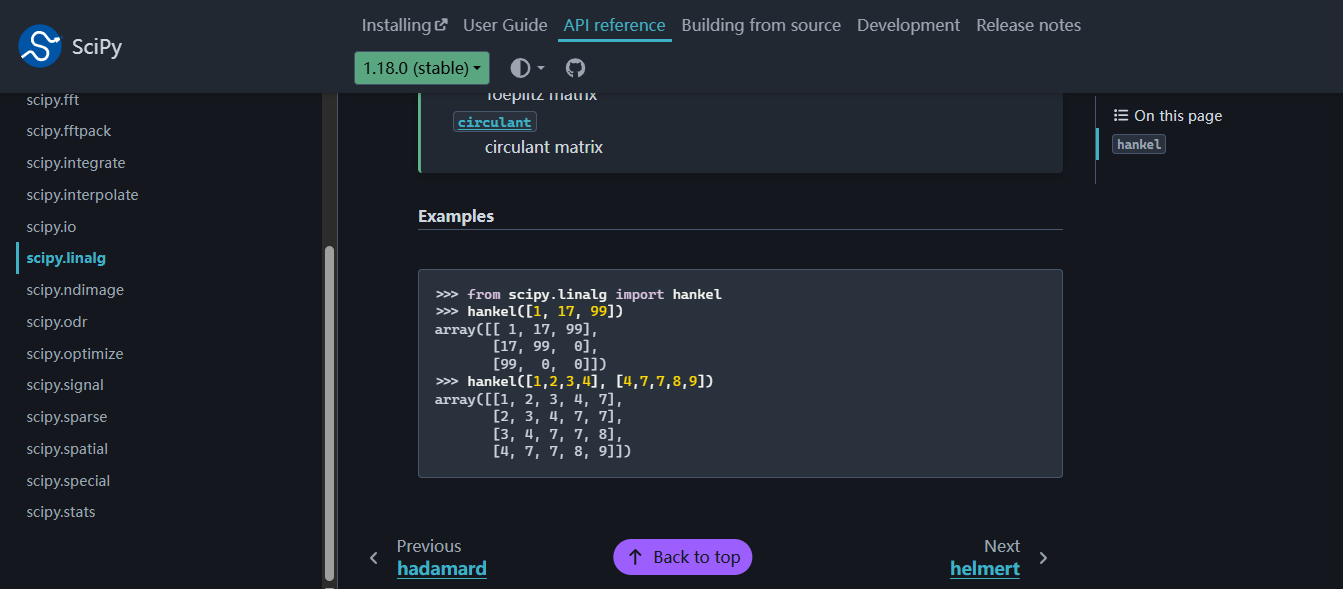

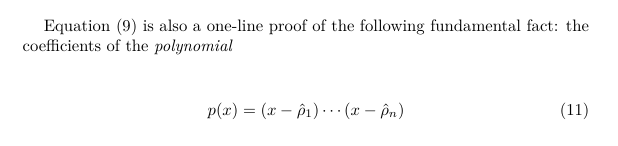

![alt text](imagens\prony.png "Title")

![alt text](imagens/recorrencialinear.png "Title")

qualquer soma de n exponenciais satisfaz uma relação de recorrência linear de ordem n

![alt text](imagens\polinomiosolucao.png "Title")

Cada rho é raiz de polinomio de grau n, se conhecer os coeficiente C, vai conseguir achar o rho

In [10]:
# --- Configurações e Alvos Teóricos ---
ht, psi = test1
omega_R_teorico, omega_I_teorico = n0
t_inicio_janela = 150.0
t_limite_busca = 800.0
n = 4  # Ordem do polinômio de Prony
passo = 1
casas_decimais = 2  # Exige que os primeiros N dígitos decimais sejam idênticos ao teórico
fator_trunc = 10**casas_decimais
min_passos_consecutivos = 1  # Exige no mínimo N janelas seguidas sem quebra temporal
nome_arquivo_saida = f"varredura_i{t_inicio_janela}_f{t_limite_busca}_n0_{numMax}.txt"
duracoes = np.arange(10.0, 40.1, 0.1)
tempo_inicio_global = time.time()
# --- NOVO: Variáveis para rastrear o máximo de modos ---
max_modos = -1
melhor_duracao = None

with open(nome_arquivo_saida, "w", encoding="utf-8") as arquivo_out:
    pbar = tqdm(duracoes, desc="Varredura Prony", unit="janela")

    for duracao_janela in pbar:
        pronyi = int(round(t_inicio_janela / ht))
        pronyf = int(round((t_inicio_janela + duracao_janela) / ht))
        pronyi_max = int(round(t_limite_busca / ht))
        itotal = pronyi_max - pronyi
        # iterações de Prony para a duração atual da janela
        candidatos = []
        i = 0

        while i <= itotal:
            pronyireal = pronyi + i * passo
            pronyfreal = pronyf + i * passo
            range_array = psi[pronyireal:pronyfreal]

            num_colunas_total = n + 1 # indica quantas colunas a matriz de Hankel terá, sendo n o número de modos que queremos extrair e +1 para incluir a coluna adicional necessária para o cálculo
            num_linhas = len(range_array) - num_colunas_total + 1 # indica quantas linhas a matriz de Hankel terá, sendo o número de linhas igual ao tamanho do array menos o número total de colunas mais 1
            # por exemplo: ψ=[ψ0​,ψ1​,ψ2​,ψ3​,ψ4​,ψ5​,ψ6​,ψ7​]
            # linha 0: [ψ0, ψ1, ψ2, ψ3, ψ4]
            # linha 1: [ψ1, ψ2, ψ3, ψ4, ψ5]
            # linha 2: [ψ2, ψ3, ψ4, ψ5, ψ6]
            # linha 3: [ψ3, ψ4, ψ5, ψ6, ψ7]

            
            if num_linhas < 1 or len(range_array) < num_colunas_total:
                i += 1 # se isso acontecer, significa que a janela de dados é muito pequena para formar uma matriz de Hankel adequada para o número de modos desejado. Nesse caso, simplesmente avançamos para a próxima iteração sem tentar calcular os modos.
                continue

            c = range_array[:num_linhas] #Define os elementos da primeira coluna
            r = range_array[num_linhas - 1 : num_linhas - 1 + num_colunas_total] #Define a última linha da matriz

            matriz_hankel_completa = hankel(c, r)
            # ou manualmente fazendo:
            # matriz_hankel_completa2 = np.zeros((num_linhas, num_colunas_total))

            # for i in range(num_linhas):
            #     matriz_hankel_completa2[i, :] = range_array[i : i + num_colunas_total]

            # if np.array_equal(matriz_hankel_completa, matriz_hankel_completa2):
            #     print("As matrizes são idênticas!")
            # else:
            #     print("As matrizes são diferentes!")
            matriz_A = matriz_hankel_completa[:, :n]#extraia o bloco contendo todas as linhas, mantendo apenas as primeiras N colunas e descartando a última
            vetor_b = -matriz_hankel_completa[:, n]#extraia a coluna N inteira ao longo de todas as linhas, convertendo essa coluna em um vetor 1D

            p_coef, residuos, posto, valores_singulares = np.linalg.lstsq(
                matriz_A, vetor_b, rcond=None
            )

            coefs_polinomio = [1.0] + list(p_coef[::-1])
            rhos = np.roots(coefs_polinomio)

            with np.errstate(invalid="ignore", divide="ignore"):
                omegas = 1j * np.log(rhos) / ht

            t_ini_real = pronyireal * ht
            t_fim_real = pronyfreal * ht
            secao_str = (
                f"Seção: {pronyireal} a {pronyfreal} "
                f"(t = {t_ini_real:.3f}M a {t_fim_real:.3f}M)"
            )

            for j, w in enumerate(omegas):
                if np.isnan(w) or np.isinf(w):
                    continue

                omega_R = w.real
                omega_I = -w.imag

                # Truncamento estrito nas N casas decimais
                trunc_R_calc = int(np.floor(abs(omega_R) * fator_trunc + 1e-9))
                trunc_R_teor = int(np.floor(omega_R_teorico * fator_trunc + 1e-9))

                trunc_I_calc = int(np.floor(omega_I * fator_trunc + 1e-9))
                trunc_I_teor = int(np.floor(omega_I_teorico * fator_trunc + 1e-9))
                # 1e-9 é adicionado para evitar problemas de arredondamento ao converter para inteiro. Isso garante que valores muito próximos do limite de truncamento sejam tratados corretamente.

                if (trunc_R_calc == trunc_R_teor) and (trunc_I_calc == trunc_I_teor):
                    erro_abs_R = abs(abs(omega_R) - omega_R_teorico)
                    erro_abs_I = abs(omega_I - omega_I_teorico)
                    candidatos.append(
                        (
                            pronyireal,
                            secao_str,
                            j + 1,
                            omega_R,
                            omega_I,
                            erro_abs_R,
                            erro_abs_I,
                        )
                    )

            i += 1

        # --- FILTRO DE CONTINUIDADE TEMPORAL ---
        candidatos_continuos = []
        if candidatos:
            blocos = []
            bloco_atual = [candidatos[0]]

            for c in candidatos[1:]:
                idx_anterior = bloco_atual[-1][0]
                idx_atual = c[0]

                if idx_atual == idx_anterior or idx_atual == idx_anterior + passo:
                    bloco_atual.append(c)
                else:
                    passos_unicos = len(set(item[0] for item in bloco_atual))
                    if passos_unicos >= min_passos_consecutivos:
                        blocos.append(bloco_atual)
                    bloco_atual = [c]

            passos_unicos = len(set(item[0] for item in bloco_atual))
            if passos_unicos >= min_passos_consecutivos:
                blocos.append(bloco_atual)

            for b in blocos:
                candidatos_continuos.extend(b)
                # Achata a lista de blocos aprovados de volta numa lista única

        # --- NOVO: Atualiza o recorde do número de modos ---
        num_modos_atual = len(candidatos_continuos)
        if num_modos_atual > max_modos:
            max_modos = num_modos_atual
            melhor_duracao = duracao_janela

        pbar.set_postfix(
            {"dur": f"{duracao_janela:.1f}M", "aprovados": len(candidatos_continuos)}
        )

        # --- GRAVAÇÃO DOS RESULTADOS ---
        arquivo_out.write("=" * 75 + "\n")
        arquivo_out.write(
            f"DURAÇÃO DA JANELA: {duracao_janela:.1f} M | PLATÔS CONTÍNUOS: {len(candidatos_continuos)} MODOS\n"
        )
        arquivo_out.write("=" * 75 + "\n")

        if not candidatos_continuos:
            arquivo_out.write(
                "Nenhum platô contínuo encontrado para esta duração.\n\n"
            )
        else:
            for idx, secao, modo, wr, wi, err_r, err_i in candidatos_continuos:
                arquivo_out.write(f"{secao}\n")
                arquivo_out.write(
                    f"  Modo {modo}: omega_R = {wr:.10f} | omega_I = {wi:.10f} "
                    f"(erro_abs_R = {err_r:.3e}, erro_abs_I = {err_i:.3e})\n\n"
                )

tempo_total = time.time() - tempo_inicio_global
print(f"\n=== VARREDURA CONCLUÍDA ===")
print(f"Tempo total de execução: {tempo_total / 60:.2f} minutos.")
# --- NOVO: Print final com o maior resultado encontrado ---
print(f"Maior número de modos filtrados: {max_modos} (na duração: {melhor_duracao:.1f} M)")

Varredura Prony:   0%|          | 0/301 [00:00<?, ?janela/s]

Varredura Prony: 100%|██████████| 301/301 [1:31:49<00:00, 18.30s/janela, dur=40.0M, aprovados=6572]


=== VARREDURA CONCLUÍDA ===
Tempo total de execução: 91.83 minutos.
Maior número de modos filtrados: 6572 (na duração: 40.0 M)


In [15]:
# --- Configurações e Alvos Teóricos ---
ht, psi = test1
omega_R_teorico, omega_I_teorico = n0
t_inicio_janela = 150.0
t_limite_busca = 800.0
n = 4  # Ordem do polinômio de Prony
passo = 1
casas_decimais = 2  # Exige que os primeiros N dígitos decimais sejam idênticos ao teórico
fator_trunc = 10**casas_decimais
min_passos_consecutivos = 1  # Exige no mínimo N janelas seguidas sem quebra temporal
nome_arquivo_saida = f"varredura_i{t_inicio_janela}_f{t_limite_busca}_n0_{numMax}v2.txt"
duracoes = np.arange(40.0, 100.1, 0.1)
tempo_inicio_global = time.time()
# --- NOVO: Variáveis para rastrear o máximo de modos ---
max_modos = -1
melhor_duracao = None

with open(nome_arquivo_saida, "w", encoding="utf-8") as arquivo_out:
    pbar = tqdm(duracoes, desc="Varredura Prony", unit="janela")

    for duracao_janela in pbar:
        pronyi = int(round(t_inicio_janela / ht))
        pronyf = int(round((t_inicio_janela + duracao_janela) / ht))
        pronyi_max = int(round(t_limite_busca / ht))
        itotal = pronyi_max - pronyi
        # iterações de Prony para a duração atual da janela
        candidatos = []
        i = 0

        while i <= itotal:
            pronyireal = pronyi + i * passo
            pronyfreal = pronyf + i * passo
            range_array = psi[pronyireal:pronyfreal]

            num_colunas_total = n + 1 # indica quantas colunas a matriz de Hankel terá, sendo n o número de modos que queremos extrair e +1 para incluir a coluna adicional necessária para o cálculo
            num_linhas = len(range_array) - num_colunas_total + 1 # indica quantas linhas a matriz de Hankel terá, sendo o número de linhas igual ao tamanho do array menos o número total de colunas mais 1
            # por exemplo: ψ=[ψ0​,ψ1​,ψ2​,ψ3​,ψ4​,ψ5​,ψ6​,ψ7​]
            # linha 0: [ψ0, ψ1, ψ2, ψ3, ψ4]
            # linha 1: [ψ1, ψ2, ψ3, ψ4, ψ5]
            # linha 2: [ψ2, ψ3, ψ4, ψ5, ψ6]
            # linha 3: [ψ3, ψ4, ψ5, ψ6, ψ7]

            
            if num_linhas < 1 or len(range_array) < num_colunas_total:
                i += 1 # se isso acontecer, significa que a janela de dados é muito pequena para formar uma matriz de Hankel adequada para o número de modos desejado. Nesse caso, simplesmente avançamos para a próxima iteração sem tentar calcular os modos.
                continue

            c = range_array[:num_linhas] #Define os elementos da primeira coluna
            r = range_array[num_linhas - 1 : num_linhas - 1 + num_colunas_total] #Define a última linha da matriz

            matriz_hankel_completa = hankel(c, r)
            # ou manualmente fazendo:
            # matriz_hankel_completa2 = np.zeros((num_linhas, num_colunas_total))

            # for i in range(num_linhas):
            #     matriz_hankel_completa2[i, :] = range_array[i : i + num_colunas_total]

            # if np.array_equal(matriz_hankel_completa, matriz_hankel_completa2):
            #     print("As matrizes são idênticas!")
            # else:
            #     print("As matrizes são diferentes!")
            matriz_A = matriz_hankel_completa[:, :n]#extraia o bloco contendo todas as linhas, mantendo apenas as primeiras N colunas e descartando a última
            vetor_b = -matriz_hankel_completa[:, n]#extraia a coluna N inteira ao longo de todas as linhas, convertendo essa coluna em um vetor 1D

            p_coef, residuos, posto, valores_singulares = np.linalg.lstsq(
                matriz_A, vetor_b, rcond=None
            )

            coefs_polinomio = [1.0] + list(p_coef[::-1])
            rhos = np.roots(coefs_polinomio)

            with np.errstate(invalid="ignore", divide="ignore"):
                omegas = 1j * np.log(rhos) / ht

            t_ini_real = pronyireal * ht
            t_fim_real = pronyfreal * ht
            secao_str = (
                f"Seção: {pronyireal} a {pronyfreal} "
                f"(t = {t_ini_real:.3f}M a {t_fim_real:.3f}M)"
            )

            for j, w in enumerate(omegas):
                if np.isnan(w) or np.isinf(w):
                    continue

                omega_R = w.real
                omega_I = -w.imag

                # Truncamento estrito nas N casas decimais
                trunc_R_calc = int(np.floor(abs(omega_R) * fator_trunc + 1e-9))
                trunc_R_teor = int(np.floor(omega_R_teorico * fator_trunc + 1e-9))

                trunc_I_calc = int(np.floor(omega_I * fator_trunc + 1e-9))
                trunc_I_teor = int(np.floor(omega_I_teorico * fator_trunc + 1e-9))
                # 1e-9 é adicionado para evitar problemas de arredondamento ao converter para inteiro. Isso garante que valores muito próximos do limite de truncamento sejam tratados corretamente.

                if (trunc_R_calc == trunc_R_teor) and (trunc_I_calc == trunc_I_teor):
                    erro_abs_R = abs(abs(omega_R) - omega_R_teorico)
                    erro_abs_I = abs(omega_I - omega_I_teorico)
                    candidatos.append(
                        (
                            pronyireal,
                            secao_str,
                            j + 1,
                            omega_R,
                            omega_I,
                            erro_abs_R,
                            erro_abs_I,
                        )
                    )

            i += 1

        # --- FILTRO DE CONTINUIDADE TEMPORAL ---
        candidatos_continuos = []
        if candidatos:
            blocos = []
            bloco_atual = [candidatos[0]]

            for c in candidatos[1:]:
                idx_anterior = bloco_atual[-1][0]
                idx_atual = c[0]

                if idx_atual == idx_anterior or idx_atual == idx_anterior + passo:
                    bloco_atual.append(c)
                else:
                    passos_unicos = len(set(item[0] for item in bloco_atual))
                    if passos_unicos >= min_passos_consecutivos:
                        blocos.append(bloco_atual)
                    bloco_atual = [c]

            passos_unicos = len(set(item[0] for item in bloco_atual))
            if passos_unicos >= min_passos_consecutivos:
                blocos.append(bloco_atual)

            for b in blocos:
                candidatos_continuos.extend(b)
                # Achata a lista de blocos aprovados de volta numa lista única

        # --- NOVO: Atualiza o recorde do número de modos ---
        num_modos_atual = len(candidatos_continuos)
        if num_modos_atual > max_modos:
            max_modos = num_modos_atual
            melhor_duracao = duracao_janela

        pbar.set_postfix(
            {"dur": f"{duracao_janela:.1f}M", "aprovados": len(candidatos_continuos)}
        )

        # --- GRAVAÇÃO DOS RESULTADOS ---
        arquivo_out.write("=" * 75 + "\n")
        arquivo_out.write(
            f"DURAÇÃO DA JANELA: {duracao_janela:.1f} M | PLATÔS CONTÍNUOS: {len(candidatos_continuos)} MODOS\n"
        )
        arquivo_out.write("=" * 75 + "\n")

        if not candidatos_continuos:
            arquivo_out.write(
                "Nenhum platô contínuo encontrado para esta duração.\n\n"
            )
        else:
            for idx, secao, modo, wr, wi, err_r, err_i in candidatos_continuos:
                arquivo_out.write(f"{secao}\n")
                arquivo_out.write(
                    f"  Modo {modo}: omega_R = {wr:.10f} | omega_I = {wi:.10f} "
                    f"(erro_abs_R = {err_r:.3e}, erro_abs_I = {err_i:.3e})\n\n"
                )

tempo_total = time.time() - tempo_inicio_global
print(f"\n=== VARREDURA CONCLUÍDA ===")
print(f"Tempo total de execução: {tempo_total / 60:.2f} minutos.")
# --- NOVO: Print final com o maior resultado encontrado ---
print(f"Maior número de modos filtrados: {max_modos} (na duração: {melhor_duracao:.1f} M)")

Varredura Prony: 100%|██████████| 601/601 [4:39:37<00:00, 27.92s/janela, dur=100.0M, aprovados=3382] 


=== VARREDURA CONCLUÍDA ===
Tempo total de execução: 279.63 minutos.
Maior número de modos filtrados: 8414 (na duração: 53.6 M)


In [16]:
# n = 0
ht, psi = test1
t_inicio_janela = 150.0
duracao_janela = 53.6
t_limite_busca = 800.0
passo = 1
i = 0
n = 4

pronyi = int(round(t_inicio_janela / ht))
pronyf = int(round((t_inicio_janela + duracao_janela) / ht))

pronyi_max = int(round(t_limite_busca / ht))
itotal = (pronyi_max - pronyi) / passo
nome_arquivo = f"resultados_i{t_inicio_janela}_f{t_limite_busca}_d{duracao_janela}_truc_{numMax}.txt"
with open(nome_arquivo, "w", encoding="utf-8") as arquivo:
    while True:
        pronyireal = pronyi + i * passo
        pronyfreal = pronyf + i * passo
        range_array = psi[pronyireal:pronyfreal]

        t_ini_real = pronyireal * ht
        t_fim_real = pronyfreal * ht

        arquivo.write(f"\n")
        arquivo.write(
            f"A seção selecionado para análise de Prony é de {pronyireal} a {pronyfreal} "
            f"(t = {t_ini_real:.3f} a {t_fim_real:.3f})\n"
        )

        num_colunas_total = n + 1
        num_linhas = len(range_array) - num_colunas_total + 1

        c = range_array[:num_linhas]
        r = range_array[num_linhas - 1 : num_linhas - 1 + num_colunas_total]

        matriz_hankel_completa = hankel(c, r)

        matriz_A = matriz_hankel_completa[:, :n]
        vetor_b = -matriz_hankel_completa[:, n]

        p_coef, residuos, posto, valores_singulares = np.linalg.lstsq(
            matriz_A, vetor_b, rcond=None
        )

        # --- Diagnóstico de condicionamento (novo) ---
        cond_number = valores_singulares[0] / valores_singulares[-1]
        arquivo.write(f"Número de condição da matriz A: {cond_number:.3e}\n")

        coefs_polinomio = [1.0] + list(p_coef[::-1])
        rhos = np.roots(coefs_polinomio)

        dt = ht
        omegas = 1j * np.log(rhos) / dt

        for j, w in enumerate(omegas):
            arquivo.write(
                f"Modo {j+1}: omega_R = {w.real:.10f} | omega_I = {-w.imag:.10f}\n"
            )
        i += 1
        if i > itotal:
            break

print(f"Janela usada: pronyi={pronyi}, pronyf={pronyf} "
      f"(t = {pronyi*ht:.3f} a {pronyf*ht:.3f}), ht={ht}")

Janela usada: pronyi=12000, pronyf=16288 (t = 150.000 a 203.600), ht=0.012500000000045475


In [17]:
def plotLogEvolutionteste(test, title=""):

    ht, psi = test

    t = ht * np.arange(1, len(psi)+1)

    plt.figure(figsize=(9,4))

    plt.semilogy(
        t,
        np.abs(psi),
        lw=2
    )

    plt.xlabel(r"$t$ ")
    plt.ylabel(r"$|\Psi|$ (escala log)")

    plt.xticks(np.arange(0, t.max()+1, 100))  # ticks de 100 em 100

    plt.grid(True)

    plt.title(title)

    plt.show()

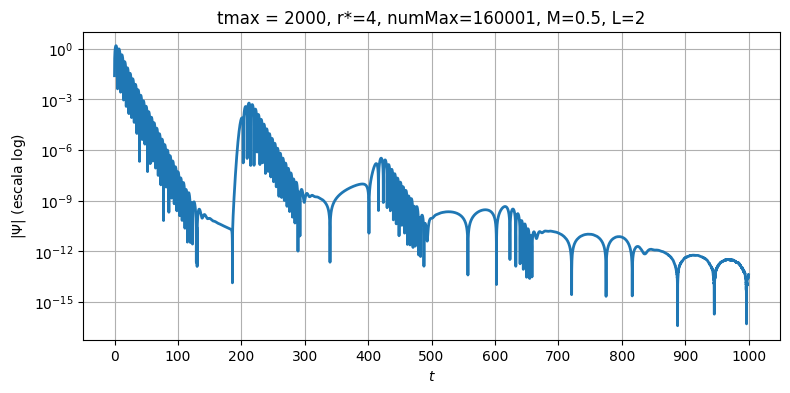

In [18]:
plotLogEvolutionteste(
    test1,
    title_str
)

In [20]:
import re

# --- Configurações ---
nome_arquivo = "resultados_i150.0_f800.0_d53.6_truc_160001.txt"  # ajuste para o seu arquivo real

omega_R_teorico, omega_I_teorico = n0  # mesma tupla teórica usada no script original
casas_decimais = 3
fator_trunc = 10**casas_decimais

# Padrão que captura cada bloco de seção: cabeçalho + número de condição + os 4 modos
padrao_secao = re.compile(
    r"A seção selecionado para análise de Prony é de (\d+) a (\d+) "
    r"\(t = ([\d.]+)M? a ([\d.]+)M?\)\s*\n"
    r"Número de condição da matriz A: ([\d.eE+-]+)\s*\n"
    r"((?:Modo \d+: omega_R = [-\d.]+ \| omega_I = [-\d.]+\s*\n?)+)"
)

padrao_modo = re.compile(
    r"Modo (\d+): omega_R = ([-\d.]+) \| omega_I = ([-\d.]+)"
)

with open(nome_arquivo, "r", encoding="utf-8") as f:
    conteudo = f.read()

candidatos_extraidos = []

for match_secao in padrao_secao.finditer(conteudo):
    idx_i, idx_f, t_ini, t_fim, num_condicao, bloco_modos = match_secao.groups()
    # bloco_modos = match_secao.group(6)

    for match_modo in padrao_modo.finditer(bloco_modos):
        modo, wr_str, wi_str = match_modo.groups()
        omega_R = float(wr_str)
        omega_I = float(wi_str)

        # mesma lógica de truncamento do script original
        trunc_R_calc = int(np.floor(abs(omega_R) * fator_trunc + 1e-9))
        trunc_R_teor = int(np.floor(omega_R_teorico * fator_trunc + 1e-9))

        trunc_I_calc = int(np.floor(omega_I * fator_trunc + 1e-9))
        trunc_I_teor = int(np.floor(omega_I_teorico * fator_trunc + 1e-9))

        if trunc_R_calc == trunc_R_teor and trunc_I_calc == trunc_I_teor:
            erro_abs_R = abs(abs(omega_R) - omega_R_teorico)
            erro_abs_I = abs(omega_I - omega_I_teorico)
            candidatos_extraidos.append(
                (int(idx_i), int(idx_f), t_ini, t_fim, modo, omega_R, omega_I, erro_abs_R, erro_abs_I)
            )

# --- Exibindo os resultados encontrados ---
print(f"Total de candidatos encontrados: {len(candidatos_extraidos)}\n")
for idx_i, idx_f, t_ini, t_fim, modo, wr, wi, err_r, err_i in candidatos_extraidos:
    print(f"Seção: {idx_i} a {idx_f} (t = {t_ini}M a {t_fim}M)")
    print(f"  Modo {modo}: omega_R = {wr:.10f} | omega_I = {wi:.10f} "
          f"(erro_abs_R = {err_r:.3e}, erro_abs_I = {err_i:.3e})\n")

Total de candidatos encontrados: 92

Seção: 39133 a 43421 (t = 489.163M a 542.763M)
  Modo 1: omega_R = -0.0546375497 | omega_I = 0.0163742274 (erro_abs_R = 3.187e-04, erro_abs_I = 3.005e-04)

Seção: 39133 a 43421 (t = 489.163M a 542.763M)
  Modo 2: omega_R = 0.0546375497 | omega_I = 0.0163742274 (erro_abs_R = 3.187e-04, erro_abs_I = 3.005e-04)

Seção: 53182 a 57470 (t = 664.775M a 718.375M)
  Modo 3: omega_R = -0.0549013532 | omega_I = 0.0162531781 (erro_abs_R = 5.485e-05, erro_abs_I = 1.794e-04)

Seção: 53182 a 57470 (t = 664.775M a 718.375M)
  Modo 4: omega_R = 0.0549013532 | omega_I = 0.0162531781 (erro_abs_R = 5.485e-05, erro_abs_I = 1.794e-04)

Seção: 53607 a 57895 (t = 670.088M a 723.688M)
  Modo 3: omega_R = -0.0542880633 | omega_I = 0.0169049417 (erro_abs_R = 6.681e-04, erro_abs_I = 8.312e-04)

Seção: 53607 a 57895 (t = 670.088M a 723.688M)
  Modo 4: omega_R = 0.0542880633 | omega_I = 0.0169049417 (erro_abs_R = 6.681e-04, erro_abs_I = 8.312e-04)

Seção: 53992 a 58280 (t = 674.

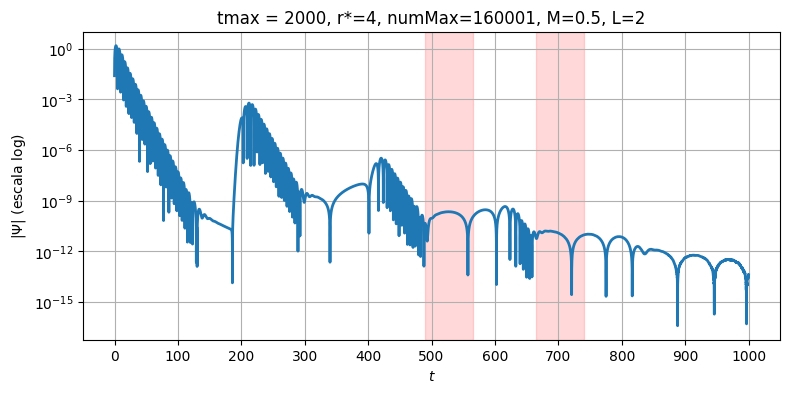

In [ ]:
from matplotlib.ticker import MultipleLocator

regiao_destacada = [
    (489.163, 564.763),  # primeira região destacada
    (664.775, 740.375)   # segunda região destacada

]
def plotLogEvolutionRed(test, title="", regioes_destacadas=None):
    ht, psi = test
    t = ht * np.arange(1, len(psi)+1)

    fig, ax = plt.subplots(figsize=(9,4))
    ax.semilogy(t, np.abs(psi), lw=2)

    ax.set_xlabel(r"$t$")
    ax.set_ylabel(r"$|\Psi|$ (escala log)")
    ax.xaxis.set_major_locator(MultipleLocator(100))
    ax.grid(True)
    ax.set_title(title)

    # --- pinta as regiões de interesse ---
    if regioes_destacadas:
        for t_ini, t_fim in regioes_destacadas:
            ax.axvspan(t_ini, t_fim, color="red", alpha=0.15)

    plt.show()

# uso, com a região que você encontrou:
plotLogEvolutionRed(
    test1,
    title="tmax = 2000, r*=4, numMax=160001, M=0.5, L=2",
    regioes_destacadas=[(489.163, 564.763), (664.775, 740.375)]
)

In [23]:
# --- Configurações e Alvos Teóricos ---
ht, psi = test1
omega_R_teorico, omega_I_teorico = n0
t_inicio_janela = 300.0
t_limite_busca = 500.0
n = 4  # Ordem do polinômio de Prony
passo = 1
casas_decimais = 2  # Exige que os primeiros N dígitos decimais sejam idênticos ao teórico
fator_trunc = 10**casas_decimais
min_passos_consecutivos = 1  # Exige no mínimo N janelas seguidas sem quebra temporal
nome_arquivo_saida = f"varredura_i{t_inicio_janela}_f{t_limite_busca}_n0_{numMax}.txt"
duracoes = np.arange(10.0, 100.1, 0.1)
tempo_inicio_global = time.time()
# --- NOVO: Variáveis para rastrear o máximo de modos ---
max_modos = -1
melhor_duracao = None

with open(nome_arquivo_saida, "w", encoding="utf-8") as arquivo_out:
    pbar = tqdm(duracoes, desc="Varredura Prony", unit="janela")

    for duracao_janela in pbar:
        pronyi = int(round(t_inicio_janela / ht))
        pronyf = int(round((t_inicio_janela + duracao_janela) / ht))
        pronyi_max = int(round(t_limite_busca / ht))
        itotal = pronyi_max - pronyi
        # iterações de Prony para a duração atual da janela
        candidatos = []
        i = 0

        while i <= itotal:
            pronyireal = pronyi + i * passo
            pronyfreal = pronyf + i * passo
            range_array = psi[pronyireal:pronyfreal]

            num_colunas_total = n + 1 # indica quantas colunas a matriz de Hankel terá, sendo n o número de modos que queremos extrair e +1 para incluir a coluna adicional necessária para o cálculo
            num_linhas = len(range_array) - num_colunas_total + 1 # indica quantas linhas a matriz de Hankel terá, sendo o número de linhas igual ao tamanho do array menos o número total de colunas mais 1
            # por exemplo: ψ=[ψ0​,ψ1​,ψ2​,ψ3​,ψ4​,ψ5​,ψ6​,ψ7​]
            # linha 0: [ψ0, ψ1, ψ2, ψ3, ψ4]
            # linha 1: [ψ1, ψ2, ψ3, ψ4, ψ5]
            # linha 2: [ψ2, ψ3, ψ4, ψ5, ψ6]
            # linha 3: [ψ3, ψ4, ψ5, ψ6, ψ7]

            
            if num_linhas < 1 or len(range_array) < num_colunas_total:
                i += 1 # se isso acontecer, significa que a janela de dados é muito pequena para formar uma matriz de Hankel adequada para o número de modos desejado. Nesse caso, simplesmente avançamos para a próxima iteração sem tentar calcular os modos.
                continue

            c = range_array[:num_linhas] #Define os elementos da primeira coluna
            r = range_array[num_linhas - 1 : num_linhas - 1 + num_colunas_total] #Define a última linha da matriz

            matriz_hankel_completa = hankel(c, r)
            # ou manualmente fazendo:
            # matriz_hankel_completa2 = np.zeros((num_linhas, num_colunas_total))

            # for i in range(num_linhas):
            #     matriz_hankel_completa2[i, :] = range_array[i : i + num_colunas_total]

            # if np.array_equal(matriz_hankel_completa, matriz_hankel_completa2):
            #     print("As matrizes são idênticas!")
            # else:
            #     print("As matrizes são diferentes!")
            matriz_A = matriz_hankel_completa[:, :n]#extraia o bloco contendo todas as linhas, mantendo apenas as primeiras N colunas e descartando a última
            vetor_b = -matriz_hankel_completa[:, n]#extraia a coluna N inteira ao longo de todas as linhas, convertendo essa coluna em um vetor 1D

            p_coef, residuos, posto, valores_singulares = np.linalg.lstsq(
                matriz_A, vetor_b, rcond=None
            )

            coefs_polinomio = [1.0] + list(p_coef[::-1])
            rhos = np.roots(coefs_polinomio)

            with np.errstate(invalid="ignore", divide="ignore"):
                omegas = 1j * np.log(rhos) / ht

            t_ini_real = pronyireal * ht
            t_fim_real = pronyfreal * ht
            secao_str = (
                f"Seção: {pronyireal} a {pronyfreal} "
                f"(t = {t_ini_real:.3f}M a {t_fim_real:.3f}M)"
            )

            for j, w in enumerate(omegas):
                if np.isnan(w) or np.isinf(w):
                    continue

                omega_R = w.real
                omega_I = -w.imag

                # Truncamento estrito nas N casas decimais
                trunc_R_calc = int(np.floor(abs(omega_R) * fator_trunc + 1e-9))
                trunc_R_teor = int(np.floor(omega_R_teorico * fator_trunc + 1e-9))

                trunc_I_calc = int(np.floor(omega_I * fator_trunc + 1e-9))
                trunc_I_teor = int(np.floor(omega_I_teorico * fator_trunc + 1e-9))
                # 1e-9 é adicionado para evitar problemas de arredondamento ao converter para inteiro. Isso garante que valores muito próximos do limite de truncamento sejam tratados corretamente.

                if (trunc_R_calc == trunc_R_teor) and (trunc_I_calc == trunc_I_teor):
                    erro_abs_R = abs(abs(omega_R) - omega_R_teorico)
                    erro_abs_I = abs(omega_I - omega_I_teorico)
                    candidatos.append(
                        (
                            pronyireal,
                            secao_str,
                            j + 1,
                            omega_R,
                            omega_I,
                            erro_abs_R,
                            erro_abs_I,
                        )
                    )

            i += 1

        # --- FILTRO DE CONTINUIDADE TEMPORAL ---
        candidatos_continuos = []
        if candidatos:
            blocos = []
            bloco_atual = [candidatos[0]]

            for c in candidatos[1:]:
                idx_anterior = bloco_atual[-1][0]
                idx_atual = c[0]

                if idx_atual == idx_anterior or idx_atual == idx_anterior + passo:
                    bloco_atual.append(c)
                else:
                    passos_unicos = len(set(item[0] for item in bloco_atual))
                    if passos_unicos >= min_passos_consecutivos:
                        blocos.append(bloco_atual)
                    bloco_atual = [c]

            passos_unicos = len(set(item[0] for item in bloco_atual))
            if passos_unicos >= min_passos_consecutivos:
                blocos.append(bloco_atual)

            for b in blocos:
                candidatos_continuos.extend(b)
                # Achata a lista de blocos aprovados de volta numa lista única

        # --- NOVO: Atualiza o recorde do número de modos ---
        num_modos_atual = len(candidatos_continuos)
        if num_modos_atual > max_modos:
            max_modos = num_modos_atual
            melhor_duracao = duracao_janela

        pbar.set_postfix(
            {"dur": f"{duracao_janela:.1f}M", "aprovados": len(candidatos_continuos)}
        )

        # --- GRAVAÇÃO DOS RESULTADOS ---
        arquivo_out.write("=" * 75 + "\n")
        arquivo_out.write(
            f"DURAÇÃO DA JANELA: {duracao_janela:.1f} M | PLATÔS CONTÍNUOS: {len(candidatos_continuos)} MODOS\n"
        )
        arquivo_out.write("=" * 75 + "\n")

        if not candidatos_continuos:
            arquivo_out.write(
                "Nenhum platô contínuo encontrado para esta duração.\n\n"
            )
        else:
            for idx, secao, modo, wr, wi, err_r, err_i in candidatos_continuos:
                arquivo_out.write(f"{secao}\n")
                arquivo_out.write(
                    f"  Modo {modo}: omega_R = {wr:.10f} | omega_I = {wi:.10f} "
                    f"(erro_abs_R = {err_r:.3e}, erro_abs_I = {err_i:.3e})\n\n"
                )

tempo_total = time.time() - tempo_inicio_global
print(f"\n=== VARREDURA CONCLUÍDA ===")
print(f"Tempo total de execução: {tempo_total / 60:.2f} minutos.")
# --- NOVO: Print final com o maior resultado encontrado ---
print(f"Maior número de modos filtrados: {max_modos} (na duração: {melhor_duracao:.1f} M)")

Varredura Prony: 100%|██████████| 901/901 [1:42:38<00:00,  6.83s/janela, dur=100.0M, aprovados=32]


=== VARREDURA CONCLUÍDA ===
Tempo total de execução: 102.64 minutos.
Maior número de modos filtrados: 318 (na duração: 67.0 M)


In [24]:
# n = 0
ht, psi = test1
t_inicio_janela = 300.0
duracao_janela = 67.0
t_limite_busca = 500.0
passo = 1
i = 0
n = 4

pronyi = int(round(t_inicio_janela / ht))
pronyf = int(round((t_inicio_janela + duracao_janela) / ht))

pronyi_max = int(round(t_limite_busca / ht))
itotal = (pronyi_max - pronyi) / passo
nome_arquivo = f"resultados_i{t_inicio_janela}_f{t_limite_busca}_d{duracao_janela}_truc_{numMax}.txt"
with open(nome_arquivo, "w", encoding="utf-8") as arquivo:
    while True:
        pronyireal = pronyi + i * passo
        pronyfreal = pronyf + i * passo
        range_array = psi[pronyireal:pronyfreal]

        t_ini_real = pronyireal * ht
        t_fim_real = pronyfreal * ht

        arquivo.write(f"\n")
        arquivo.write(
            f"A seção selecionado para análise de Prony é de {pronyireal} a {pronyfreal} "
            f"(t = {t_ini_real:.3f} a {t_fim_real:.3f})\n"
        )

        num_colunas_total = n + 1
        num_linhas = len(range_array) - num_colunas_total + 1

        c = range_array[:num_linhas]
        r = range_array[num_linhas - 1 : num_linhas - 1 + num_colunas_total]

        matriz_hankel_completa = hankel(c, r)

        matriz_A = matriz_hankel_completa[:, :n]
        vetor_b = -matriz_hankel_completa[:, n]

        p_coef, residuos, posto, valores_singulares = np.linalg.lstsq(
            matriz_A, vetor_b, rcond=None
        )

        # --- Diagnóstico de condicionamento (novo) ---
        cond_number = valores_singulares[0] / valores_singulares[-1]
        arquivo.write(f"Número de condição da matriz A: {cond_number:.3e}\n")

        coefs_polinomio = [1.0] + list(p_coef[::-1])
        rhos = np.roots(coefs_polinomio)

        dt = ht
        omegas = 1j * np.log(rhos) / dt

        for j, w in enumerate(omegas):
            arquivo.write(
                f"Modo {j+1}: omega_R = {w.real:.10f} | omega_I = {-w.imag:.10f}\n"
            )
        i += 1
        if i > itotal:
            break

print(f"Janela usada: pronyi={pronyi}, pronyf={pronyf} "
      f"(t = {pronyi*ht:.3f} a {pronyf*ht:.3f}), ht={ht}")

Janela usada: pronyi=24000, pronyf=29360 (t = 300.000 a 367.000), ht=0.012500000000045475
